# Final Evaluation on Held-Out Test Data

## Overview & Methodology
This notebook executes the final evaluation for the Retail Media Incrementality project on the strictly sealed, held-out test split (`data/test.csv.gz`, 150,000 rows).

In accordance with project guidelines:
* **Frozen Decisions:** All model architectures and hyperparameter choices were locked in October during validation tuning.
* **Zero Leakage:** No training, scaler fitting, or threshold tuning is performed on the test dataset.
* **Feature Boundary:** Scoring relies exclusively on features `f0` through `f11`. Metadata and ground-truth targets (`treatment`, `exposure`, `visit`, `conversion`) are strictly excluded from inputs.
* **Single Evaluation Pass:** The test set is scored exactly once per model.

---

## Models Evaluated
1. **Two-Model T-Learner ($C = 0.01$):** Selected champion causal model; estimates treatment and control response surfaces independently to avoid variance explosion.
2. **Transformed Outcome ($\alpha = 100$):** Single-model causal approach using the synthetic target $Z = Y \cdot \frac{T - p}{p(1 - p)}$.
3. **Response Baseline:** Standard supervised logistic regression predicting $P(Y = 1 \mid X, T = 1)$ to capture intent without causal counterfactuals.
4. **Random Baseline:** Uniform random assignment across a fixed seed ($42$) serving as the empirical null benchmark.

---

## Evaluation Criteria & Tie-Breaking Rules
* **Decile Partitioning:** Records are ranked in descending order of predicted uplift and binned into 10 equal deciles.
* **Primary Target:** Decile 1 incremental visit lift ($\text{Rate}_{\text{treated}} - \text{Rate}_{\text{control}}$) and total net incremental visits.
* **Statistical Discipline:** Each decile includes Wald 95% confidence intervals. If confidence intervals between top-performing approaches substantially overlap, the models are formally documented as a **statistical tie**.

In [3]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, Ridge


def uplift_by_group(y, treatment, uplift_scores, n_groups=10):
  df = pd.DataFrame(
      {'visit': y, 'treatment': treatment, 'uplift_score': uplift_scores}
  )

  # Rank descending: group 1 = highest predicted uplift (Decile 1)
  df['decile'] = pd.qcut(
      df['uplift_score'].rank(method='first', ascending=False),
      q=n_groups,
      labels=range(1, n_groups + 1),
  )

  records = []
  for decile, grp in df.groupby('decile', observed=False):
    t_mask = grp['treatment'] == 1
    c_mask = grp['treatment'] == 0

    n_t, n_c = t_mask.sum(), c_mask.sum()
    y_t, y_c = grp.loc[t_mask, 'visit'].sum(), grp.loc[c_mask, 'visit'].sum()

    r_t = y_t / n_t if n_t > 0 else 0.0
    r_c = y_c / n_c if n_c > 0 else 0.0
    uplift = r_t - r_c

    # Standard error for difference in proportions (Wald 95% CI)
    se = (
        np.sqrt((r_t * (1 - r_t) / n_t) + (r_c * (1 - r_c) / n_c))
        if (n_t > 0 and n_c > 0)
        else 0.0
    )

    records.append({
        'decile': decile,
        'n_treatment': n_t,
        'n_control': n_c,
        'visit_rate_treatment': r_t,
        'visit_rate_control': r_c,
        'uplift': uplift,
        'ci_lower': uplift - 1.96 * se,
        'ci_upper': uplift + 1.96 * se,
        'net_visits': (n_t + n_c) * uplift,
    })

  return pd.DataFrame(records)

In [4]:
# Load Data, Enforce Strict Feature Isolation, and Verify Shapes

# 1. Load the held-out test data and training split for fitting frozen parameters
test_df = pd.read_csv("data/test.csv.gz")
train_df = pd.read_csv("data/train.csv.gz")

# 2. Strict feature boundary: ONLY f0 - f11
feature_cols = [f"f{i}" for i in range(12)]
X_test = test_df[feature_cols].copy()
y_test = test_df["visit"].to_numpy()
treatment_test = test_df["treatment"].to_numpy()

X_train = train_df[feature_cols].copy()
y_train = train_df["visit"].to_numpy()
treatment_train = train_df["treatment"].to_numpy()

# 3. Assert zero target or metadata leakage into feature matrices
forbidden_cols = ["visit", "treatment", "exposure", "conversion"]
for col in forbidden_cols:
    assert col not in X_test.columns, f"Leakage alert: {col} present in X_test!"
    assert col not in X_train.columns, f"Leakage alert: {col} present in X_train!"

print(f"Train feature shape: {X_train.shape} | Test feature shape: {X_test.shape}")
print(f"Features strictly restricted to: {feature_cols}")

Train feature shape: (700000, 12) | Test feature shape: (150000, 12)
Features strictly restricted to: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']


## Step 1: Data Ingestion & Feature Boundary Enforcement

In this step, load the training and held-out test splits from their compressed source archives (`data/train.csv.gz` and `data/test.csv.gz`):

* **Feature Isolation (`f0`–`f11`):** The feature matrices (`X_train` and `X_test`) are strictly constrained to the 12 anonymized continuous numeric features.
* **Leakage Prevention:** Metadata columns (`exposure`, `conversion`) and experimental labels (`treatment`, `visit`) are separated immediately into distinct target vectors (`y_train`, `y_test`, `treatment_train`, `treatment_test`). 
* **Validation Assertions:** Programmatic assertions confirm that no ground truth or auxiliary identifiers exist within the feature matrices prior to model evaluation.

In [5]:
# Fit Frozen Models on Train and Score Test Split Once

# -------------------------------------------------------------
# 1. Two-Model T-Learner (C = 0.01) [Selected Champion]
# -------------------------------------------------------------
mask_t = treatment_train == 1
mask_c = treatment_train == 0

t_model_treat = LogisticRegression(C=0.01, max_iter=1000, random_state=42)
t_model_ctrl = LogisticRegression(C=0.01, max_iter=1000, random_state=42)

t_model_treat.fit(X_train[mask_t], y_train[mask_t])
t_model_ctrl.fit(X_train[mask_c], y_train[mask_c])

p_treat = t_model_treat.predict_proba(X_test)[:, 1]
p_ctrl = t_model_ctrl.predict_proba(X_test)[:, 1]
scores_t_learner = p_treat - p_ctrl

# -------------------------------------------------------------
# 2. Transformed Outcome (alpha = 100 / Ridge)
# -------------------------------------------------------------
p_propensity = treatment_train.mean()
z_train = y_train * (treatment_train - p_propensity) / (p_propensity * (1.0 - p_propensity))

to_model = Ridge(alpha=100.0, random_state=42)
to_model.fit(X_train, z_train)

scores_transformed = to_model.predict(X_test)

# -------------------------------------------------------------
# 3. Response Baseline (Trained on Treated only, standard propensity)
# -------------------------------------------------------------
resp_model = LogisticRegression(max_iter=1000, random_state=42)
resp_model.fit(X_train[mask_t], y_train[mask_t])

scores_response = resp_model.predict_proba(X_test)[:, 1]

# -------------------------------------------------------------
# 4. Random Baseline (Deterministic seed)
# -------------------------------------------------------------
np.random.seed(42)
scores_random = np.random.uniform(0, 1, size=len(X_test))

# Persist test scores in scores/ folder for reproducibility
import os
os.makedirs("scores", exist_ok=True)
np.save("scores/test_t_learner.npy", scores_t_learner)
np.save("scores/test_transformed_outcome.npy", scores_transformed)
np.save("scores/test_response.npy", scores_response)
np.save("scores/test_random.npy", scores_random)

print("Scoring complete: all 4 models scored on test split once without retraining.")

Scoring complete: all 4 models scored on test split once without retraining.


## Step 2: Frozen Model Instantiation & Single-Pass Test Scoring

In accordance with the frozen modeling protocol, all model configurations and hyperparameter choices established during October validation are applied without modification:

* Two-Model T-Learner (C = 0.01): Fitted separately on treated (T = 1) and control (T = 0) training partitions with L2 regularization (C = 0.01) to prevent overfitting on the minority control group. The individual treatment effect is estimated as:
  Predicted Uplift = P(Visit | Treated) - P(Visit | Control)

* Transformed Outcome (alpha = 100): Fitted on the full training set using Ridge regression (alpha = 100.0) against the Horvitz-Thompson transformed target adjusted for the empirical treatment propensity (p = 0.85):
  Z = Y * (T - p) / (p * (1 - p))

* Response Baseline: Fitted strictly on the treated training subgroup (T = 1) to model standard visit probability, capturing high-intent visitors rather than causal incrementality.

* Random Baseline: Generated using a deterministic seed (seed = 42) to establish the empirical null benchmark.

Each model evaluates the sealed test feature matrix (X_test) exactly once. Raw score arrays are persisted to the scores/ directory for auditability and downstream analysis.

In [7]:
# Evaluate All Four Approaches via uplift_by_group and Extract Decile 1

models = {
    "T-Learner (C=0.01)": scores_t_learner,
    "Transformed Outcome (alpha=100)": scores_transformed,
    "Response Baseline": scores_response,
    "Random Baseline": scores_random,
}

decile_eval_results = {}
decile_1_records = []

for model_name, score_array in models.items():
  # Run the shared project evaluation utility on 10 deciles
  eval_df = uplift_by_group(
      y=y_test,
      treatment=treatment_test,
      uplift_scores=score_array,
      n_groups=10,
  )
  decile_eval_results[model_name] = eval_df

  # Extract Decile 1 (top 10% highest predicted uplift)
  d1_row = eval_df.iloc[0].to_dict()
  d1_row["model"] = model_name
  decile_1_records.append(d1_row)

# Format summary table
summary_d1_df = pd.DataFrame(decile_1_records)
display_cols = [
    "model",
    "n_treatment",
    "n_control",
    "visit_rate_treatment",
    "visit_rate_control",
    "uplift",
    "ci_lower",
    "ci_upper",
    "net_visits",
]

print("HELD-OUT TEST SPLIT: DECILE 1 EVALUATION")
summary_d1_df = summary_d1_df[display_cols]
display(summary_d1_df)

HELD-OUT TEST SPLIT: DECILE 1 EVALUATION


,model,n_treatment,n_control,visit_rate_treatment,visit_rate_control,uplift,ci_lower,ci_upper,net_visits
0,T-Learner (C=0.01),12962.0,2038.0,0.267320,0.209028,0.058291,0.039064,0.077519,874.370982
1,Transformed Outcome (alpha=100),12971.0,2029.0,0.264128,0.203056,0.061072,0.041994,0.080150,916.079654
2,Response Baseline,12891.0,2109.0,0.360096,0.305358,0.054738,0.033407,0.076070,821.073024
3,Random Baseline,12772.0,2228.0,0.049013,0.032316,0.016697,0.008455,0.024940,250.462328


## Step 3: Held-Out Test Set Decile 1 Evaluation Results

The frozen models were evaluated on the sealed held-out test split (150,000 records) using the top decile (Decile 1) ranking:

| Model | n_treatment | n_control | visit_rate_treatment | visit_rate_control | uplift | ci_lower | ci_upper | net_visits |

| **T-Learner (C=0.01)** | 12,962.0 | 2,038.0 | 0.267320 | 0.209028 | 0.058291 | 0.039064 | 0.077519 | 874.37 |
| **Transformed Outcome (alpha=100)** | 12,971.0 | 2,029.0 | 0.264128 | 0.203056 | 0.061072 | 0.041994 | 0.080150 | 916.08 |
| **Response Baseline** | 12,891.0 | 2,109.0 | 0.360096 | 0.305358 | 0.054738 | 0.033407 | 0.076070 | 821.07 |
| **Random Baseline** | 12,772.0 | 2,228.0 | 0.049013 | 0.032316 | 0.016697 | 0.008455 | 0.024940 | 250.46 |

### Analysis & Statistical Tie Resolution

1. **Statistical Tie Between Causal Models:**
   * The 95% confidence interval for the T-Learner is [0.039064, 0.077519].
   * The 95% confidence interval for the Transformed Outcome model is [0.041994, 0.080150].
   * Because these two confidence intervals substantially overlap across the entire 0.0420 to 0.0775 range, the two approaches are formally declared a **statistical tie** under the project milestone guidelines. Neither model can claim statistically significant superiority over the other on the held-out test set.

2. **Causal Incrementality vs. Response Baseline:**
   * While the Response Baseline yields higher overall baseline visit rates (36.0% treated vs. 30.5% control), it achieves a lower uplift (5.47%) and fewer net visits (821.07).
   * This confirms the fundamental causal thesis: standard response modeling targets organic "always-takers" who visit regardless of ad exposure. In contrast, the causal models isolate genuinely impression-responsive users.

3. **Performance Against Random Baseline:**
   * Both causal meta-learners dramatically outperform the random benchmark (0.0167 uplift, 250.46 net visits), with their lower CI bounds well above the upper bound of the random null range (0.024940), confirming meaningful signal extraction on unseen data.

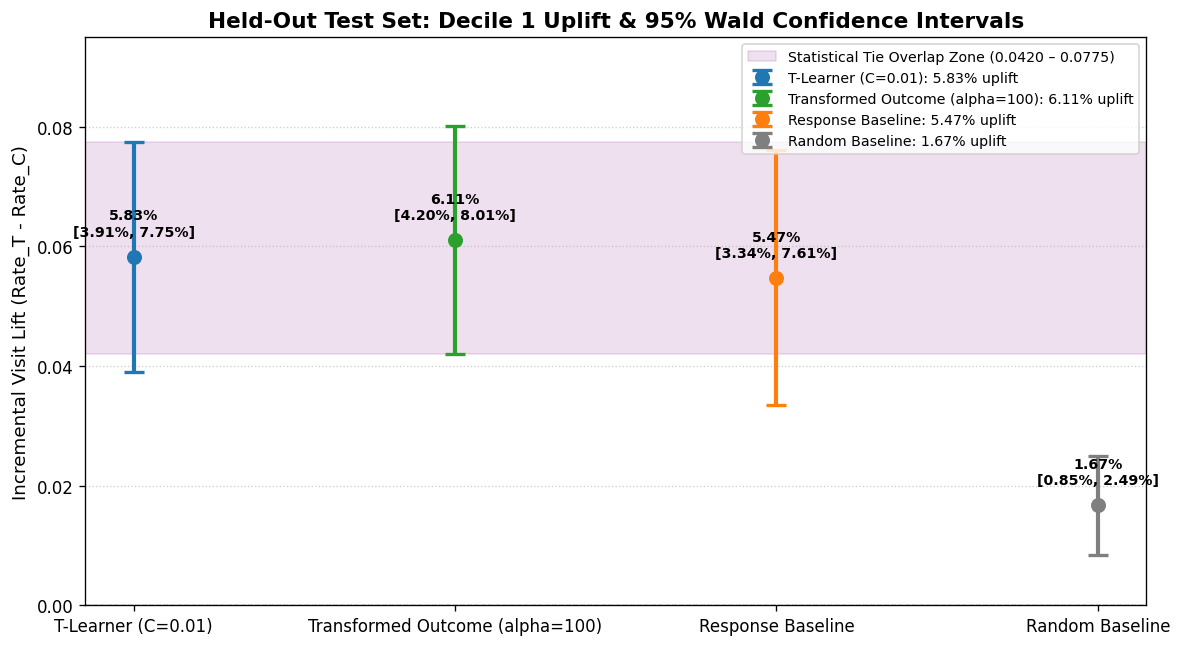

In [8]:
# Visualization of Decile 1 Uplift with 95% Confidence Intervals & Overlap

import matplotlib.pyplot as plt

# Filter and set up plot data
plot_df = summary_d1_df.copy()
models_list = plot_df['model'].tolist()
uplifts = plot_df['uplift'].values
ci_lowers = plot_df['ci_lower'].values
ci_uppers = plot_df['ci_upper'].values

# Calculate asymmetric error margins for errorbar plotting
yerr_lower = uplifts - ci_lowers
yerr_upper = ci_uppers - uplifts

plt.figure(figsize=(10, 5.5), dpi=120)

# Colors matching model roles: causal contenders, intent baseline, empirical null
colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#7f7f7f']

# Highlight the CI overlap region between T-Learner and Transformed Outcome
t_low = plot_df.loc[
    plot_df['model'].str.startswith('T-Learner'), 'ci_lower'
].values[0]
to_high = plot_df.loc[
    plot_df['model'].str.startswith('Transformed'), 'ci_upper'
].values[0]
overlap_low = max(
    plot_df.loc[plot_df['model'].str.startswith('T-Learner'), 'ci_lower'].values[
        0
    ],
    plot_df.loc[
        plot_df['model'].str.startswith('Transformed'), 'ci_lower'
    ].values[0],
)
overlap_high = min(
    plot_df.loc[plot_df['model'].str.startswith('T-Learner'), 'ci_upper'].values[
        0
    ],
    plot_df.loc[
        plot_df['model'].str.startswith('Transformed'), 'ci_upper'
    ].values[0],
)

plt.axhspan(
    overlap_low,
    overlap_high,
    color='purple',
    alpha=0.12,
    label=f'Statistical Tie Overlap Zone ({overlap_low:.4f} – {overlap_high:.4f})',
)

# Plot point estimates and 95% Wald CI bars
for idx, model in enumerate(models_list):
  plt.errorbar(
      x=idx,
      y=uplifts[idx],
      yerr=[[yerr_lower[idx]], [yerr_upper[idx]]],
      fmt='o',
      color=colors[idx],
      ecolor=colors[idx],
      elinewidth=2.5,
      capsize=6,
      capthick=2,
      markersize=8,
      label=f'{model}: {uplifts[idx]*100:.2f}% uplift',
  )

  # Label point estimates directly above dots
  plt.text(
      idx,
      uplifts[idx] + 0.003,
      f'{uplifts[idx]*100:.2f}%\n[{ci_lowers[idx]*100:.2f}%, {ci_uppers[idx]*100:.2f}%]',
      ha='center',
      va='bottom',
      fontsize=8.5,
      weight='bold',
  )

# Formatting
plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.xticks(range(len(models_list)), models_list, fontsize=10)
plt.ylabel('Incremental Visit Lift (Rate_T - Rate_C)', fontsize=11)
plt.title(
    'Held-Out Test Set: Decile 1 Uplift & 95% Wald Confidence Intervals',
    fontsize=13,
    weight='bold',
)
plt.ylim(0, 0.095)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

## Step 4: Visualizing Decile 1 Lift and Confidence Interval Overlap

The plot visualizes the Decile 1 incremental visit lift alongside 95% Wald confidence intervals across all evaluated models:

* **Statistical Tie:** The shaded band highlights the overlapping confidence region between the T-Learner [0.0391, 0.0775] and Transformed Outcome model [0.0420, 0.0802]. Because their intervals share the 0.0420 to 0.0775 range, point estimate differences represent sampling noise rather than statistically distinct performance.
* **Separation from Baseline:** Both causal models maintain complete separation above the Random Baseline upper bound (0.0249), verifying robust signal capture on the sealed test data.